# 03 Analysis: hypothesis tests H1-H3
Definitions and falsification conditions: `reports/framing.md`. Data: `data/project.db` (tables built by `sql/02`, `sql/03`).

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = sqlite3.connect(ROOT / "data" / "project.db")

## H1: concentration of public-hospital usage among shortage-affected ingredients
False if the top 10% of ingredients account for <= 50% of S94 PUB prescriptions.

PRIMARY (ingredients with S94 PUB rx): n=489, top10% k=49, share=70.3% -> H1 TRUE
SENSITIVITY (in item map, no public rx = 0): n=698, top10% k=70, share=78.1% -> H1 TRUE


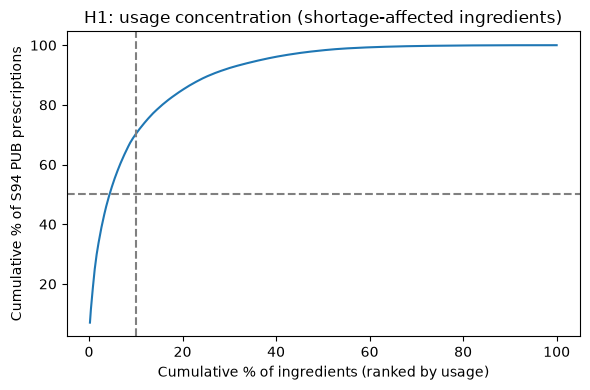

                    ingredient_key  total_prescriptions  n_episodes  n_critical  avg_duration_days
0                        OXYCODONE             209387.0          37           0              116.0
1            FERRIC CARBOXYMALTOSE             133435.0           5           0              115.0
2                     PANTOPRAZOLE             108426.0          71           0               70.7
3    AMOXICILLIN + CLAVULANIC ACID             101921.0          50           0              130.2
4                       ENOXAPARIN              95055.0          23          11               15.8
5                     PREDNISOLONE              94732.0           4           1               26.5
6                        CEFALEXIN              75990.0          46           0               82.5
7  SULFAMETHOXAZOLE + TRIMETHOPRIM              70388.0          21           1              111.5
8                    DEXAMETHASONE              60412.0          17           6               54.9
9         

In [2]:
ing = pd.read_sql_query("SELECT * FROM out_ingredient_shortage", con)
inmap = pd.read_sql_query(
    "SELECT ingredient_key, MAX(in_pbs_map) AS in_map FROM tga_episodes "
    "WHERE no_ingredient = 0 AND ingredient_key IS NOT NULL GROUP BY ingredient_key", con)
ing = ing.merge(inmap, on="ingredient_key", how="left")

def h1(df, label):
    d = df.sort_values("total_prescriptions", ascending=False).reset_index(drop=True)
    n = len(d)
    k = int(np.ceil(0.10 * n))
    share = d["total_prescriptions"].iloc[:k].sum() / d["total_prescriptions"].sum()
    print(f"{label}: n={n}, top10% k={k}, share={share:.1%} -> H1 {'TRUE' if share > 0.5 else 'FALSE'}")
    return d, share

d, h1_share = h1(ing[ing.matched_public == 1], "PRIMARY (ingredients with S94 PUB rx)")
sens = ing[ing.in_map == 1].copy()
sens["total_prescriptions"] = sens["total_prescriptions"].fillna(0)
_, h1_share_sens = h1(sens, "SENSITIVITY (in item map, no public rx = 0)")

cum = d["total_prescriptions"].cumsum() / d["total_prescriptions"].sum()
x = np.arange(1, len(d) + 1) / len(d)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x * 100, cum * 100)
ax.axvline(10, ls="--", c="grey")
ax.axhline(50, ls="--", c="grey")
ax.set_xlabel("Cumulative % of ingredients (ranked by usage)")
ax.set_ylabel("Cumulative % of S94 PUB prescriptions")
ax.set_title("H1: usage concentration (shortage-affected ingredients)")
fig.tight_layout()
fig.savefig(FIG / "h1_concentration.png", dpi=150)
plt.show()
cols = ["ingredient_key", "total_prescriptions", "n_episodes", "n_critical", "avg_duration_days"]
print(d.head(10)[cols].to_string())

## H2: resolution speed of Critical vs other shortages
False if median duration of Critical >= median of all other ratings.

8295 resolved episodes with valid duration
0 duplicates on (artg_id, start_date), dropped
8295 episodes after dedup; duration_days == 0: 702
rating
Low         5042
Medium      2403
Critical     747
High         103
                n  median        mean    q1     q3
is_critical                                       
False        7548    56.0   94.793190  22.0  120.0
True          747    45.0  101.736278  17.0  105.0
             n  median
rating                
Critical   747    45.0
High       103    74.0
Low       5042    58.0
Medium    2403    50.0
PRIMARY: median Critical=45.0 vs non-Critical=56.0 -> H2 TRUE
SENSITIVITY (non-Critical = Low+Medium): 45.0 vs 56.0 -> TRUE


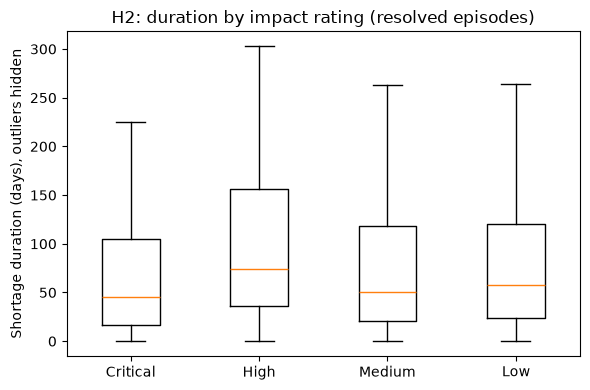

In [3]:
ep = pd.read_sql_query(
    "SELECT artg_id, supply_impact_start_date AS start_date, supply_impact_end_date AS end_date, "
    "shortage_impact_rating AS rating, source, duration_days FROM tga_episodes "
    "WHERE episode_type = 'resolved' AND valid_duration = 1", con)
print(len(ep), "resolved episodes with valid duration")
print(ep.duplicated(["artg_id", "start_date"]).sum(), "duplicates on (artg_id, start_date), dropped")
ep = ep.drop_duplicates(["artg_id", "start_date"]).copy()
print(len(ep), "episodes after dedup; duration_days == 0:", int((ep.duration_days == 0).sum()))
print(ep.rating.value_counts(dropna=False).to_string())

ep["is_critical"] = ep.rating == "Critical"
summ = ep.groupby("is_critical")["duration_days"].agg(
    n="count", median="median", mean="mean",
    q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
print(summ.to_string())
print(ep.groupby("rating")["duration_days"].agg(n="count", median="median").to_string())

med_c = ep.loc[ep.is_critical, "duration_days"].median()
med_n = ep.loc[~ep.is_critical, "duration_days"].median()
print(f"PRIMARY: median Critical={med_c:.1f} vs non-Critical={med_n:.1f} -> H2 {'TRUE' if med_c < med_n else 'FALSE'}")
med_n2 = ep.loc[ep.rating.isin(["Low", "Medium"]), "duration_days"].median()
print(f"SENSITIVITY (non-Critical = Low+Medium): {med_c:.1f} vs {med_n2:.1f} -> {'TRUE' if med_c < med_n2 else 'FALSE'}")

order = ["Critical", "High", "Medium", "Low"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([ep.loc[ep.rating == r, "duration_days"] for r in order], tick_labels=order, showfliers=False)
ax.set_ylabel("Shortage duration (days), outliers hidden")
ax.set_title("H2: duration by impact rating (resolved episodes)")
fig.tight_layout()
fig.savefig(FIG / "h2_duration_by_rating.png", dpi=150)
plt.show()

## H3: usage in shortage start month vs mean of 3 preceding months
True if median ratio < 1. Unit = episode (ingredient-month rows weighted by n_episodes).

ingredient-month rows=904; full 3-month baseline=809; baseline>0=809; rx NULL in start month (among full baseline)=4
PRIMARY: ingredient-months n=805, median=0.997, share<1=50.8%
   episode-weighted n=1070, median=0.998, share<1=50.5%
SENSITIVITY (NULL start month = 0 rx): ingredient-months n=809, median=0.996, share<1=51.1%
   episode-weighted n=1078, median=0.997, share<1=50.8%
SUBSET (episodes with a Critical rating): ingredient-months n=46, median=0.999, share<1=50.0%
   episode-weighted n=55, median=0.997, share<1=52.7%


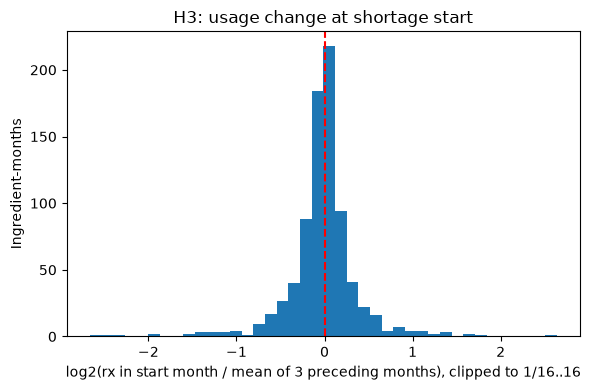

In [4]:
h3 = pd.read_sql_query("SELECT * FROM out_h3_base", con)
full = h3[h3.n_prev3 == 3]
print(f"ingredient-month rows={len(h3)}; full 3-month baseline={len(full)}; baseline>0={int((full.avg_prev3 > 0).sum())}; "
      f"rx NULL in start month (among full baseline)={int(full.prescriptions.isna().sum())}")

valid = h3[(h3.n_prev3 == 3) & (h3.avg_prev3 > 0) & h3.prescriptions.notna()].copy()
valid["ratio"] = valid.prescriptions / valid.avg_prev3

def summarize(df, label):
    r = np.repeat(df["ratio"].to_numpy(), df["n_episodes"].astype(int).to_numpy())
    print(f"{label}: ingredient-months n={len(df)}, median={df.ratio.median():.3f}, share<1={(df.ratio < 1).mean():.1%}")
    print(f"   episode-weighted n={len(r)}, median={np.median(r):.3f}, share<1={(r < 1).mean():.1%}")
    return float(np.median(r))

h3_med = summarize(valid, "PRIMARY")
alt = full[full.avg_prev3 > 0].copy()
alt["prescriptions"] = alt.prescriptions.fillna(0)
alt["ratio"] = alt.prescriptions / alt.avg_prev3
summarize(alt, "SENSITIVITY (NULL start month = 0 rx)")
summarize(valid[valid.has_critical == 1], "SUBSET (episodes with a Critical rating)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(np.log2(valid.ratio.clip(lower=1 / 16, upper=16)), bins=40)
ax.axvline(0, c="red", ls="--")
ax.set_xlabel("log2(rx in start month / mean of 3 preceding months), clipped to 1/16..16")
ax.set_ylabel("Ingredient-months")
ax.set_title("H3: usage change at shortage start")
fig.tight_layout()
fig.savefig(FIG / "h3_ratio_distribution.png", dpi=150)
plt.show()

## Effect sizes and uncertainty
Verdicts above follow the locked rules in `framing.md`. This block adds 95% bootstrap CIs (5,000 resamples, seed 42), a sign test and a control for H2/H3.

In [5]:
# EFFECT-SIZES
from math import comb
rng = np.random.default_rng(42)
B = 5000

c = ep.loc[ep.is_critical, "duration_days"].to_numpy()
o = ep.loc[~ep.is_critical, "duration_days"].to_numpy()
d2 = np.array([np.median(rng.choice(c, len(c))) - np.median(rng.choice(o, len(o))) for _ in range(B)])
print(f"H2: median diff (Critical - other) = {np.median(c) - np.median(o):.1f} days, 95% CI [{np.percentile(d2, 2.5):.1f}, {np.percentile(d2, 97.5):.1f}]")
print(f"H2: mean diff = {c.mean() - o.mean():.1f} days; share >180 days: Critical={(c > 180).mean():.1%}, other={(o > 180).mean():.1%}")

r = valid["ratio"].to_numpy()
b3 = np.array([np.median(rng.choice(r, len(r))) for _ in range(B)])
n_lt, n_gt = int((r < 1).sum()), int((r > 1).sum())
n3 = n_lt + n_gt
p = min(1.0, 2 * sum(comb(n3, i) for i in range(min(n_lt, n_gt) + 1)) / 2 ** n3)
print(f"H3: median ratio={np.median(r):.3f}, 95% CI [{np.percentile(b3, 2.5):.3f}, {np.percentile(b3, 97.5):.3f}]; below1={n_lt}, above1={n_gt}, sign test p={p:.3f}")

w = pd.read_sql_query("SELECT prescriptions, avg_prev3, n_prev3 FROM out_rx_window WHERE month >= '2024-10-01' AND month < '2026-05-01'", con)
w = w[(w.n_prev3 == 3) & (w.avg_prev3 > 0) & w.prescriptions.notna()]
print(f"H3 control (all ingredient-months, same window): n={len(w)}, median ratio={(w.prescriptions / w.avg_prev3).median():.3f}")


H2: median diff (Critical - other) = -11.0 days, 95% CI [-18.0, -6.0]
H2: mean diff = 6.9 days; share >180 days: Critical=12.7%, other=14.4%
H3: median ratio=0.997, 95% CI [0.985, 1.004]; below1=409, above1=380, sign test p=0.319
H3 control (all ingredient-months, same window): n=11225, median ratio=0.995


## Verdicts

In [6]:
print(f"H1: top10% share={h1_share:.1%} -> {'TRUE' if h1_share > 0.5 else 'FALSE'}")
print(f"H2: median Critical={med_c:.1f} vs non-Critical={med_n:.1f} -> {'TRUE' if med_c < med_n else 'FALSE'}")
print(f"H3: median ratio={h3_med:.3f} -> {'TRUE' if h3_med < 1 else 'FALSE'}")

H1: top10% share=70.3% -> TRUE
H2: median Critical=45.0 vs non-Critical=56.0 -> TRUE
H3: median ratio=0.998 -> TRUE


## Conclusions
- **H1 TRUE.** The top 10% of shortage-affected ingredients (49 of 489) account for 70.3% of S94 PUB prescriptions (sensitivity, 698 ingredients with absent usage = 0: 78.1%). No control against all PBS ingredients, so this does not show shortage-affected ingredients are more concentrated than average.
- **H2 TRUE.** Median duration of Critical shortages is 45 days vs 56 days for other ratings (difference -11 days, 95% bootstrap CI [-18, -6]). Mean difference is +6.9 days (Critical higher); share of episodes over 180 days is 12.7% (Critical) vs 14.4% (other). Resolved episodes only (ongoing shortages excluded).
- **H3 TRUE by the locked rule, no detectable effect.** Median ratio 0.997 (95% CI [0.985, 1.004]); sign test p = 0.319 (409 below 1, 380 above 1); control median over all ingredient-months in the same window is 0.995. Public-hospital prescriptions show no measurable drop in the shortage start month.

In [1]:
import sqlite3
import pandas as pd

ro = sqlite3.connect("file:../data/project.db?mode=ro", uri=True)
r = pd.read_sql_query("SELECT * FROM out_risk_ranking", ro)
d = pd.read_sql_query("SELECT robust_top30 FROM out_dash_ranking", ro)

def spearman(a, b):
    return r[a].rank().corr(r[b].rank())

def top30(col):
    return set(r.loc[r[col] <= 30, "ingredient_key"])

print("ranked:", len(r), "| robust_top30:", int(d["robust_top30"].sum()))
print("Spearman main/alt, main/alt2, alt/alt2:",
      round(spearman("risk_score", "risk_score_alt"), 3),
      round(spearman("risk_score", "risk_score_alt2"), 3),
      round(spearman("risk_score_alt", "risk_score_alt2"), 3))
print("top-30 overlap main/alt, main/alt2:",
      len(top30("risk_rank") & top30("risk_rank_alt")),
      len(top30("risk_rank") & top30("risk_rank_alt2")))

ranked: 489 | robust_top30: 20
Spearman main/alt, main/alt2, alt/alt2: 0.984 0.981 0.963
top-30 overlap main/alt, main/alt2: 23 23
